# Лабораторная работа № 3 — задание 2

Выполняли Свешников Борис — ИСУ 467394 и Хасанов Дмитрий — ИСУ 467920.

## Полное условие задания (вариант 2)

Постройте два асимптотических доверительных интервала уровня $1-\alpha$ для указанного параметра. Проведите эксперимент по схеме, аналогичной первой задаче, и сравните два доверительных интервала.

Задача представлена в 5 вариантах. Сначала указывается класс распределений (однопараметрический) и оцениваемый параметр, затем параметры эксперимента и подсказки.

**Вариант 2.**

- Класс распределений: распределение Лапласса с неизвестным параметром сдвига $\mu$ и единичным масштабирующим параметром.
- Оцениваемый параметр: $\mu$.
- Параметры эксперимента: $\mu=2$.
- Подсказка: асимптотическая нормальность выборочных среднего и медианы.

**Схема эксперимента из задания 1, на которую ссылается условие.** Проведите эксперимент по построению доверительных интервалов в зависимости от объемов выборки: задайте массив объемов выборок, для каждого объема выборки сгенерируйте соответствующее количество выборок, для каждой посчитайте доверительный интервал, обработайте результаты, например, посчитайте долю «хороших» интервалов для каждого объема выборки, проанализируйте границы, и т. п. Как изменился результат? Как объяснить?

## Вычисление варианта

В `Lab 3.pdf` есть пять вариантов, но правило выбора не приведено.
Продолжаем соглашение второго задания из `matstat-2`: сумма **цифр** ИСУ по модулю количества вариантов плюс один.
Это принятое соглашение явно отделяем от текста условия:

$$4+6+7+3+9+4=33,\qquad4+6+7+9+2+0=28,$$

$$(33+28)\bmod5+1=61\bmod5+1=1+1=\boxed2.$$

В обоих интервалах используем только данные и известный единичный масштаб; истинное $\mu=2$ нужно для генерации и проверки покрытия.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
from scipy import stats
from IPython.display import Image, Markdown, display

from utils.intervals import (
    laplace_intervals, laplace_median_coverage,
    laplace_median_exact_halfwidth,
)
from utils.experiments import run_laplace_experiment, paired_coverage_difference
from plots.laplace import laplace_theory_plots, laplace_result_plots

SEED = 24422442
ALPHA = 0.05
MU = 2.0
SCALE = 1.0
M = 20_000
# Нечётные n задают медиану как единственную центральную порядковую статистику.
N = np.array([3, 5, 11, 21, 51, 101, 301, 1001, 3001])
ISU = (467394, 467920)
DIGIT_SUM = sum(int(digit) for number in ISU for digit in str(number))
VARIANT = DIGIT_SUM % 5 + 1
OUTPUT_DIR = Path("images/laplace_location")
RESULT_DIR = Path("results")
RESULT_DIR.mkdir(exist_ok=True)
pd.set_option("display.max_columns", 16)
pd.set_option("display.width", 160)
Z = stats.norm.ppf(1-ALPHA/2)

print(f"Вариант: {VARIANT}; μ={MU}; b={SCALE}; z={Z:.6f}; повторений: {M:,}")
print("Объёмы:", N)

Вариант: 2; μ=2.0; b=1.0; z=1.959964; повторений: 20,000
Объёмы: [   3    5   11   21   51  101  301 1001 3001]


## Модель Лапласа: плотность, функция распределения и моменты

Запишем плотность сначала с произвольным масштабом $b>0$:

$$f_{\mu,b}(x)=\frac1{2b}\exp\left(-\frac{|x-\mu|}{b}\right),\qquad x\in\mathbb R.$$

В нашей задаче **$b=1$ известен**, поэтому это однопараметрическая модель по $\mu$.
Нормировка следует из симметрии и замены $t=|x-\mu|/b$:

$$\int_{-\infty}^{\infty}f_{\mu,b}(x)\,dx
=2\int_0^\infty\frac1{2b}e^{-t/b}\,dt=1.$$

Для $W=X-\mu$ плотность симметрична относительно нуля, поэтому $\mathbb EW=0$ и

$$\boxed{\mathbb EX=\mu.}$$

Дисперсию найдём интегрированием, используя $\int_0^\infty u^2e^{-u}du=\Gamma(3)=2$:

$$\operatorname{Var}(X)=\mathbb EW^2
=\frac1b\int_0^\infty t^2e^{-t/b}\,dt
=b^2\int_0^\infty u^2e^{-u}\,du
=\boxed{2b^2}.$$

Интегрируя плотность слева и справа от $\mu$, получаем

$$F_{\mu,b}(x)=\begin{cases}
\frac12 e^{(x-\mu)/b},&x\le\mu,\\
1-\frac12 e^{-(x-\mu)/b},&x>\mu.
\end{cases}$$

Следовательно $F_{\mu,b}(\mu)=1/2$, то есть **медиана также равна $\mu$**, и
$f_{\mu,b}(\mu)=1/(2b)$.
Обе рассматриваемые статистики оценивают один параметр, но обладают разными дисперсиями.

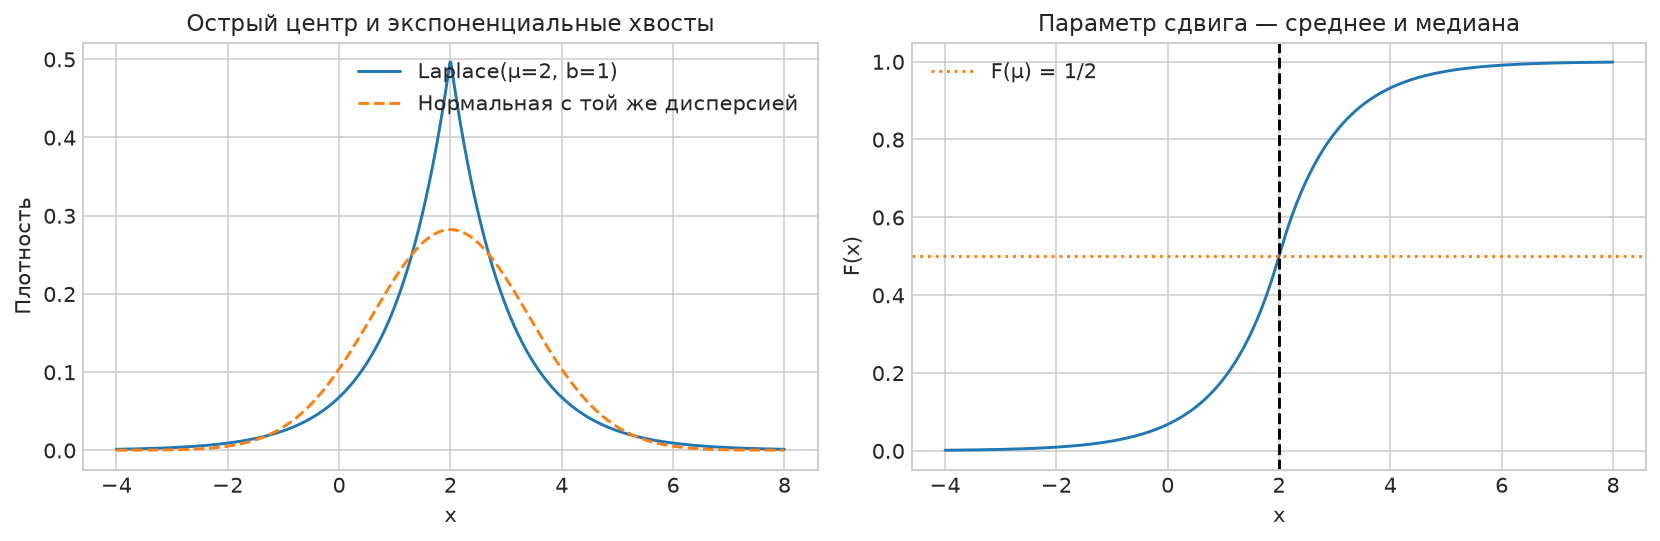

In [2]:
theory_images = laplace_theory_plots(OUTPUT_DIR)
display(Image(filename=str(theory_images["model"])))

## Первый интервал: выборочное среднее

Выборочное среднее равно

$$\overline X_n=\frac1n\sum_{i=1}^nX_i.$$

По линейности ожидания $\mathbb E\overline X_n=\mu$. В силу независимости

$$\operatorname{Var}(\overline X_n)
=\frac1{n^2}\sum_{i=1}^n\operatorname{Var}(X_i)=\frac{2b^2}{n}.$$

Это точные равенства для любого $n$. Но нормальность среднего не является точной при конечном $n$: отдельные наблюдения распределены по Лапласу.
По центральной предельной теореме

$$\sqrt n(\overline X_n-\mu)\xrightarrow d\mathcal N(0,2b^2),$$

или после деления на стандартное отклонение предельного закона

$$Z_n^{(\mathrm{mean})}=\frac{\sqrt n(\overline X_n-\mu)}{\sqrt2\,b}
\xrightarrow d\mathcal N(0,1).$$

Пусть $z=z_{1-\alpha/2}=\Phi^{-1}(1-\alpha/2)>0$. Тогда

$$\mathbb P\left(-z\le\frac{\sqrt n(\overline X_n-\mu)}{\sqrt2\,b}\le z\right)\longrightarrow1-\alpha.$$

Умножая на положительное $\sqrt2b/\sqrt n$, получаем
$-z b\sqrt{2/n}\le\overline X_n-\mu\le z b\sqrt{2/n}$.
Переносим $\mu$ и $\overline X_n$ в соответствующие части:

$$\boxed{I_{\mathrm{mean}}=
\left[\overline X_n-zb\sqrt{\frac2n},\quad
\overline X_n+zb\sqrt{\frac2n}\right].}$$

При $b=1$ неизвестных параметров в полуширине нет, оценивать дисперсию дополнительно не нужно.
Для $\alpha=0.05$ длина равна

$$\ell_{\mathrm{mean}}=2z\sqrt{2/n}\approx\frac{5.5436}{\sqrt n}.$$

## Второй интервал: выборочная медиана

Для $n=2k-1$ определяем медиану как центральную порядковую статистику

$$\widetilde X_n=X_{(k)},\qquad k=(n+1)/2.$$

Для чётного $n$ `numpy.median` усредняет две центральные порядковые статистики. Предельный закон тот же, но конечновыборочные формулы ниже относятся именно к нечётному $n$.
Поэтому в эксперименте выбираем нечётные объёмы.

### Предельный закон медианы

Для $f(\mu)>0$ выборочная медиана асимптотически нормальна (Лимар, теорема о выборочных квантилях, Thm 4.5):

$$\sqrt n(\widetilde X_n-\mu)\xrightarrow d\mathcal N\left(0,\frac1{4f(\mu)^2}\right).$$

Идея доказательства: событие $\{\sqrt n(\widetilde X_n-\mu)\le t\}$ означает, что хотя бы $k$ наблюдений не больше $\mu+t/\sqrt n$; их число биномиально, и к нему применяется ЦПТ. Условие теоремы — только дифференцируемость $F$ в точке $\mu$ и $f(\mu)>0$, поэтому излом плотности Лапласа в $\mu$ не мешает.

Для Лапласа $f(\mu)=1/(2b)$, поэтому $1/[4f(\mu)^2]=b^2$ и

$$\sqrt n(\widetilde X_n-\mu)\xrightarrow d\mathcal N(0,b^2).$$

Это **асимптотическая** дисперсия нормированного отклонения, а не точное равенство $\operatorname{Var}(\widetilde X_n)=b^2/n$ при конечном $n$.

### Обращение предельного нормального неравенства

Из

$$\frac{\sqrt n(\widetilde X_n-\mu)}b\xrightarrow d\mathcal N(0,1)$$

получаем центральную область

$$-z\le\frac{\sqrt n(\widetilde X_n-\mu)}b\le z.$$

После умножения на $b/\sqrt n$ и переноса неизвестного параметра:

$$\boxed{I_{\mathrm{median}}=
\left[\widetilde X_n-\frac{zb}{\sqrt n},\quad
\widetilde X_n+\frac{zb}{\sqrt n}\right].}$$

При $b=1$ и уровне $95\%$

$$\ell_{\mathrm{median}}=\frac{2z}{\sqrt n}\approx\frac{3.9199}{\sqrt n}.$$

Ни в одном из двух интервалов неизвестное $\mu$ не входит в границы иначе как через оценку по наблюдениям.
Квантили стандартного нормального распределения общие для обоих методов.

In [3]:
# Пример: одна выборка, две оценки и два интервала.
rng_demo = np.random.default_rng(SEED + 101)
sample = rng_demo.laplace(MU, SCALE, size=11)
intervals = laplace_intervals(sample, ALPHA, SCALE)
print("Наблюдения:", np.round(sample, 3))
print(f"Среднее: {sample.mean():.6f}; медиана: {np.median(sample):.6f}")
for method, (low, high) in intervals.items():
    print(f"{method:6s}: [{low:.6f}, {high:.6f}], длина={high-low:.6f}, накрывает μ: {bool(low <= MU <= high)}")

Наблюдения: [ 4.123  2.517 -0.722  2.902  1.399  1.748  1.133  2.402  2.832  2.584
  1.836]
Среднее: 2.068432; медиана: 2.402404
mean  : [1.232700, 2.904163], длина=1.671463, накрывает μ: True
median: [1.811452, 2.993355], длина=1.181903, накрывает μ: True


## Предварительное сравнение

Оба интервала имеют асимптотический уровень $1-\alpha$, а их длины детерминированы при фиксированном $n$, поскольку масштаб известен:

$$\frac{\ell_{\mathrm{median}}}{\ell_{\mathrm{mean}}}=\frac1{\sqrt2}\approx0.7071.$$

Таким образом, медианный интервал примерно на $29.3\%$ короче. Асимптотические дисперсии оценок соотносятся как $b^2:(2b^2)=1:2$.
Для одинаковой асимптотической длины среднему требуется примерно вдвое больше наблюдений.

Однако меньшая длина сама по себе не доказывает преимущество при малом $n$:
сначала нужно проверить **фактическое покрытие**.
Предельная нормальность гарантирует только сходимость вероятности к $1-\alpha$ при $n\to\infty$.

### Состоятельность и симметрия оценок

По закону больших чисел $\overline X_n\xrightarrow p\mu$.
Для медианы, например при $\varepsilon>0$, вероятность $\widetilde X_n>\mu+\varepsilon$ означает, что не более половины наблюдений лежат ниже $\mu+\varepsilon$, хотя их истинная доля равна $F(\mu+\varepsilon)>1/2$.
Закон больших чисел для индикаторов делает эту вероятность стремящейся к нулю; левый хвост аналогичен.
Поэтому $\widetilde X_n\xrightarrow p\mu$ и все четыре границы стягиваются к $\mu$.

Распределение выборки сохраняется при отражении $X_i\mapsto2\mu-X_i$. Среднее и медиана при этом переходят в $2\mu-\widehat\mu$.
Значит, их распределения симметричны относительно $\mu$. Оба ожидания существуют, поэтому **обе оценки несмещённые** для каждого рассматриваемого $n$.
Для медианы существование ожидания следует, например, из
$|\widetilde X_n-\mu|\le\max_i|X_i-\mu|\le\sum_i|X_i-\mu|$.
Следовательно, MSE обеих оценок совпадает с их дисперсией, хотя её эмпирические оценки слегка отличаются из-за конечного числа повторений и разных делителей в выборочной дисперсии.

## Точное конечновыборочное покрытие медианного интервала

Чтобы оценить ошибку асимптотики независимо от Монте-Карло, найдём истинную вероятность покрытия построенного медианного интервала.

Пусть $h=z/\sqrt n$ при $b=1$. Тогда

$$\mu\in[\widetilde X_n-h,\widetilde X_n+h]
\iff\mu-h\le\widetilde X_n\le\mu+h.$$

Вероятность наблюдению попасть левее $\mu-h$ равна

$$p_-=F(\mu-h)=\frac12e^{-h}.$$

Медиана лежит левее $\mu-h$, если хотя бы $k=(n+1)/2$ наблюдений оказались левее этой границы:

$$\mathbb P(\widetilde X_n<\mu-h)
=\mathbb P\{\operatorname{Bin}(n,p_-)\ge k\}.$$

Из симметрии правый хвост имеет ту же вероятность. Значит,

$$\boxed{c_{\mathrm{median}}(n)
=1-2\mathbb P\left\{\operatorname{Bin}\left(n,\tfrac12e^{-z/\sqrt n}\right)\ge\frac{n+1}2\right\}.}$$

Это точная формула **покрытия асимптотического интервала**, а не утверждение, что сам интервал имеет точный уровень $95\%$.
Масштаб и сдвиг из вероятности исчезают, если использовать правильную полуширину $zb/\sqrt n$.

На рисунке показана плотность нормированного отклонения $T_n=\sqrt n(\widetilde X_n-\mu)$:
$g_{T_n}(t)=g_n(\mu+t/\sqrt n)/\sqrt n$.
Множитель $1/\sqrt n$ — якобиан замены переменной.

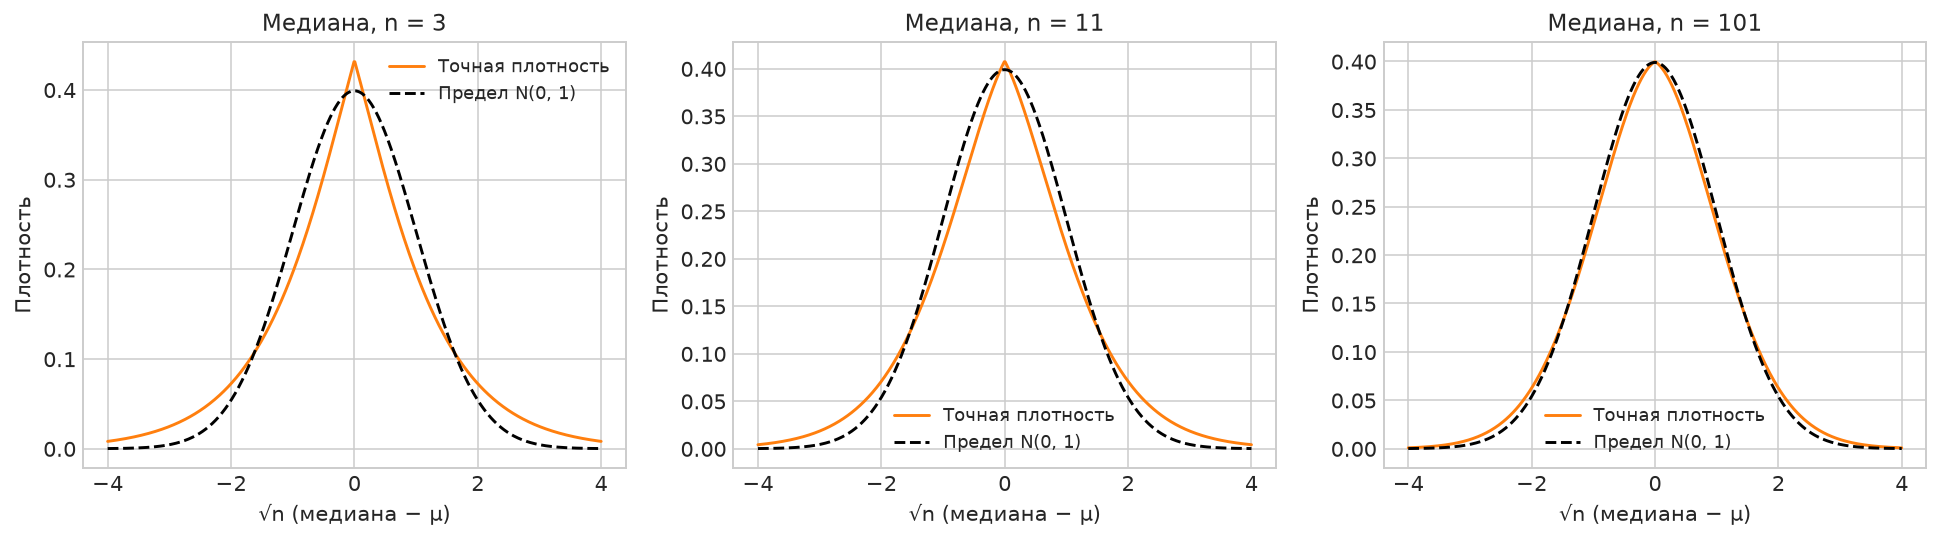

In [4]:
display(Image(filename=str(theory_images["median_limit"])))

In [5]:
reference = pd.DataFrame({
    "n": N,
    "median_exact_coverage": [laplace_median_coverage(int(n), ALPHA) for n in N],
})
display(reference.round(6))

,n,median_exact_coverage
0,3,0.860744
1,5,0.871317
2,11,0.890234
3,21,0.904356
4,51,0.919551
5,101,0.928039
6,301,0.937139
7,1001,0.942918
8,3001,0.945905


## Вычислительный эксперимент

Для каждого $n$ генерируем $M=20000$ независимых выборок $X_i\sim\operatorname{Laplace}(2,1)$.
**На одной и той же выборке** вычисляем среднее, медиану и оба интервала: это парное сравнение.
Случайные генераторы для двух заданий и для демонстрационных примеров используют отдельные фиксированные seed, поэтому примеры не меняют основной эксперимент.

Для каждого метода считаем:

$$\widehat c=\frac1M\sum_{j=1}^M\mathbb1(L_j\le\mu\le U_j),\qquad
\widehat{\operatorname{Bias}}=\frac1M\sum_j(\widehat\mu_j-\mu),$$

$$\widehat{\operatorname{Var}}=\frac1{M-1}\sum_j(\widehat\mu_j-\overline{\widehat\mu})^2,
\qquad
\widehat{\operatorname{MSE}}=\frac1M\sum_j(\widehat\mu_j-\mu)^2.$$

Дополнительно сохраняем границы, длины, доли промахов слева и справа.
Для покрытия показываем точечные 95%-интервалы Уилсона: они отражают конечное число симуляций, а не ошибку асимптотического метода.
При вероятности около $0.95$ типичная стандартная ошибка покрытия равна $\sqrt{0.95\cdot0.05/20000}\approx0.00154$.

Даже если кривые покрытия на двух соседних объёмах немного меняют направление, это может быть обычный шум Монте-Карло. Для медианы точная формула позволяет проверить это без угадывания по графику.

In [6]:
experiment = run_laplace_experiment(N, M, SEED+2, ALPHA, MU)
table = experiment["table"]
paired = paired_coverage_difference(experiment)
table.to_csv(RESULT_DIR / "task_2_summary.csv", index=False)
paired.to_csv(RESULT_DIR / "task_2_paired.csv", index=False)
result_images = laplace_result_plots(experiment, paired, OUTPUT_DIR)
display(table[["n", "method", "coverage", "mc_low", "mc_high", "exact_coverage", "mean_length", "bias", "variance", "mse"]].round(6))

,n,method,coverage,mc_low,mc_high,exact_coverage,mean_length,bias,variance,mse
0,3,mean,0.94240,0.939085,0.945545,NaN,3.200608,0.000159,0.678086,0.678052
1,3,median,0.85895,0.854057,0.863705,0.860744,2.263171,0.004998,0.654581,0.654573
2,5,mean,0.94750,0.944322,0.950506,NaN,2.479180,0.003061,0.395763,0.395752
3,5,median,0.87100,0.866283,0.875574,0.871317,1.753045,0.001726,0.346824,0.346810
4,11,mean,0.94685,0.943654,0.949874,NaN,1.671463,0.004205,0.181768,0.181777
5,11,median,0.88925,0.884826,0.893525,0.890234,1.181903,0.002536,0.139075,0.139075
6,21,mean,0.94745,0.944271,0.950457,NaN,1.209716,0.000519,0.095466,0.095461
7,21,median,0.90570,0.901571,0.909673,0.904356,0.855398,0.000900,0.065885,0.065882
8,51,mean,0.94835,0.945196,0.951332,NaN,0.776261,0.001279,0.039365,0.039365
9,51,median,0.91795,0.914066,0.921674,0.919551,0.548900,0.001462,0.024248,0.024249


## Покрытие: главный результат сравнения

Точки с полосами на первом рисунке — Монте-Карло, сплошная линия у медианы — конечновыборочная вероятность по выведенной формуле.
Поэтому систематическое отставание медианного интервала от $0.95$ не следует объяснять только случайностью симуляции.

В этой модели асимптотическое приближение медианы сходится заметно медленнее: при $n=3$ фактическое покрытие около $0.861$, при $n=101$ около $0.928$, при $n=1001$ около $0.943$.
Даже при $n=3001$ оно около $0.946$, а не ровно $0.95$.
У среднего в эксперименте покрытие от $0.942$ при $n=3$ до $0.95$ при больших $n$: отклонение от номинала намного меньше, чем у медианы.
Для медианы указаны значения точной вероятности, а не результата случайного запуска.

Медианный интервал действительно короче, но на небольших выборках часть выигрыша в длине сопровождается недопокрытием.
Сравнение методов требует одновременно учитывать обе характеристики.

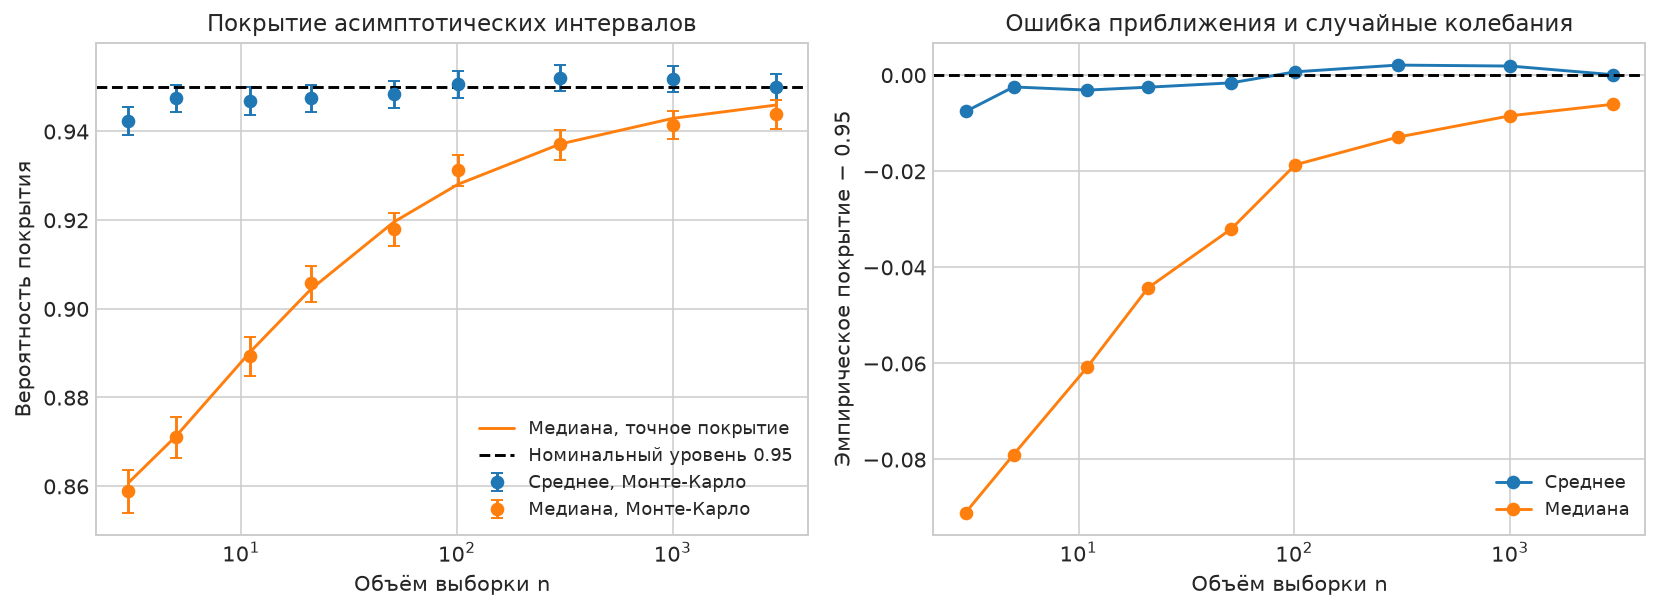

In [7]:
display(Image(filename=str(result_images["coverage"])))

## Реализации интервалов на общих данных

В каждой колонке показаны первые 60 одинаковых выборок для двух методов.
Для верхней и нижней панели одной колонки горизонтальные пределы совпадают, чтобы длины можно было сравнить визуально.
Красный отрезок — промах. При фиксированном методе и $n$ все отрезки одинаковой длины; случайно меняется только центр.

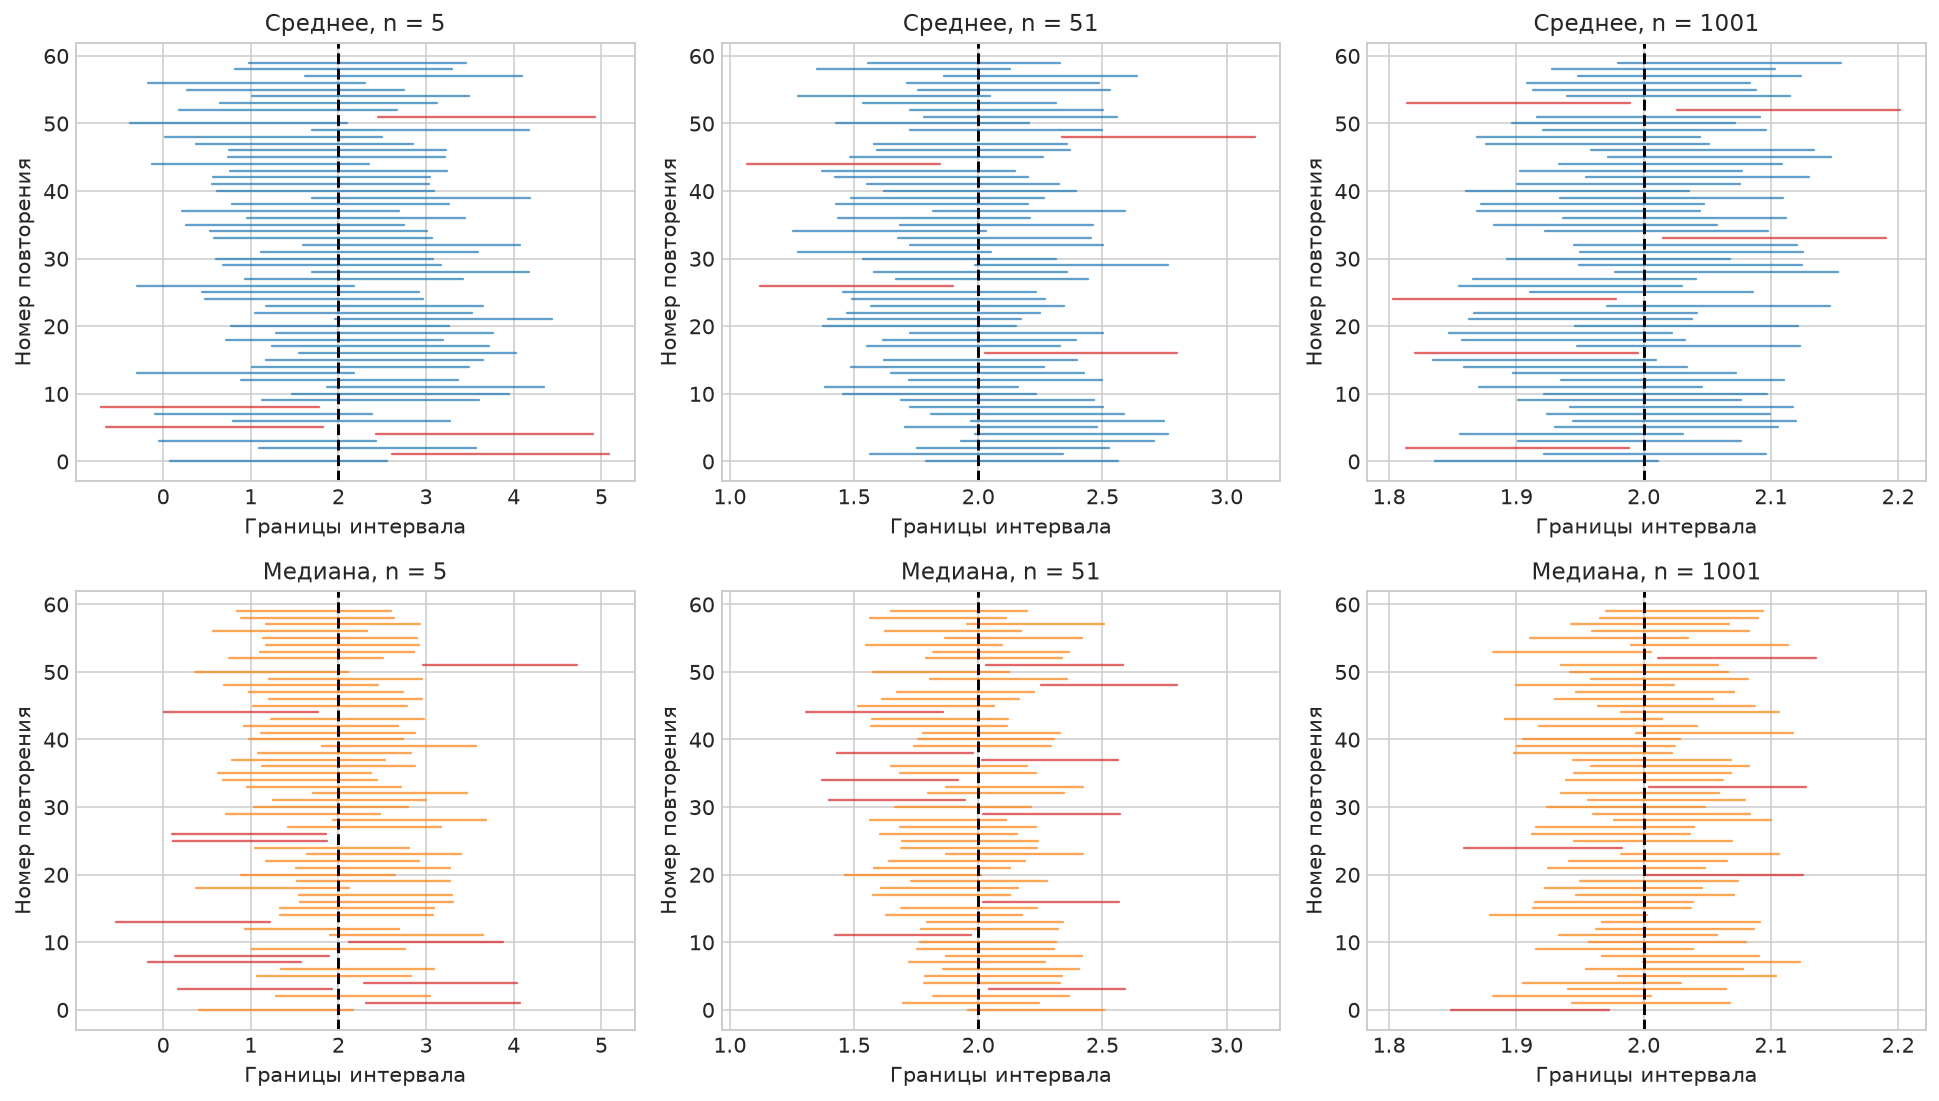

In [8]:
display(Image(filename=str(result_images["intervals"])))

## Длины и скорость сужения

Обе длины имеют точную зависимость $C/\sqrt n$ уже как функции построенных интервалов, независимо от того, насколько хорошо выполняется нормальная аппроксимация:

$$\sqrt n\,\ell_{\mathrm{mean}}=2z\sqrt2,\qquad
\sqrt n\,\ell_{\mathrm{median}}=2z.$$

Поэтому на нормированном графике получаются горизонтальные линии.
В отличие от первого задания, длины здесь не случайны и не имеют тяжёлого хвоста: масштаб известен.
Чтобы вдвое уменьшить длину любого из двух интервалов, надо увеличить $n$ в четыре раза.

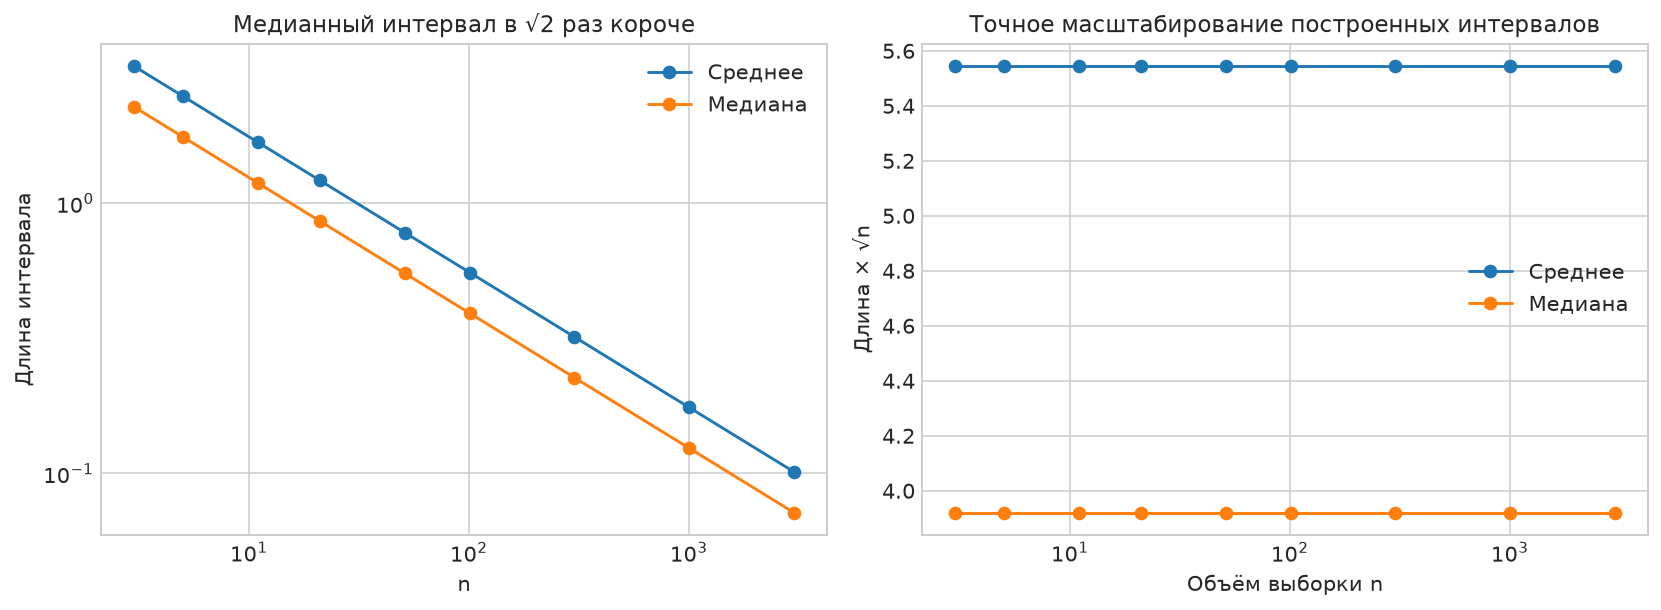

Отношение длин на всех объёмах: [0.707107 0.707107 0.707107 0.707107 0.707107 0.707107 0.707107 0.707107
 0.707107]


In [9]:
display(Image(filename=str(result_images["length"])))
mean_lengths = table[table.method == "mean"].set_index("n").mean_length
median_lengths = table[table.method == "median"].set_index("n").mean_length
np.testing.assert_allclose(median_lengths/mean_lengths, 1/np.sqrt(2))
print("Отношение длин на всех объёмах:", np.round((median_lengths/mean_lengths).to_numpy(), 6))

## Разброс оценок и MSE

Для среднего $n\operatorname{Var}(\overline X_n)=2$ при любом $n$.
Для медианы её асимптотический закон предсказывает $n\operatorname{Var}(\widetilde X_n)\to1$.
Одной сходимости по распределению вообще недостаточно для сходимости дисперсий; в модели Лапласа нужный переход можно обосновать равномерной интегрируемостью.

Действительно, при $b=1$, $t\ge0$ биномиальная оценка Чернова даёт

$$\mathbb P\{\widetilde X_n-\mu>t\}
\le[4q_t(1-q_t)]^{n/2},\qquad q_t=\tfrac12e^{-t}.$$

Здесь событие означает, что как минимум половина наблюдений больше $\mu+t$.
При $0\le t\le1$ величина $-\log[4q_t(1-q_t)]$ ограничена снизу положительной константой, умноженной на $t^2$;
при $t\ge1$ — положительной константой, умноженной на $t$.
После замены $t=u/\sqrt n$ и учёта симметрии получаем равномерно по $n$ интегрируемую хвостовую оценку вида
$\mathbb P(\sqrt n|\widetilde X_n-\mu|>u)\le2\exp[-c\min(u^2,u)]$ для некоторой константы $c>0$.
Она обеспечивает ограниченность моментов порядка выше второго, а значит равномерную интегрируемость квадратов.
Поэтому из предельного закона действительно следует предел вторых моментов и дисперсий.

На левой панели проверяем нормированные дисперсии, на правой — MSE и асимптотические ориентиры $2/n$, $1/n$.
Несмещённость не означает отсутствия колебаний эмпирического смещения на конечных $M$.

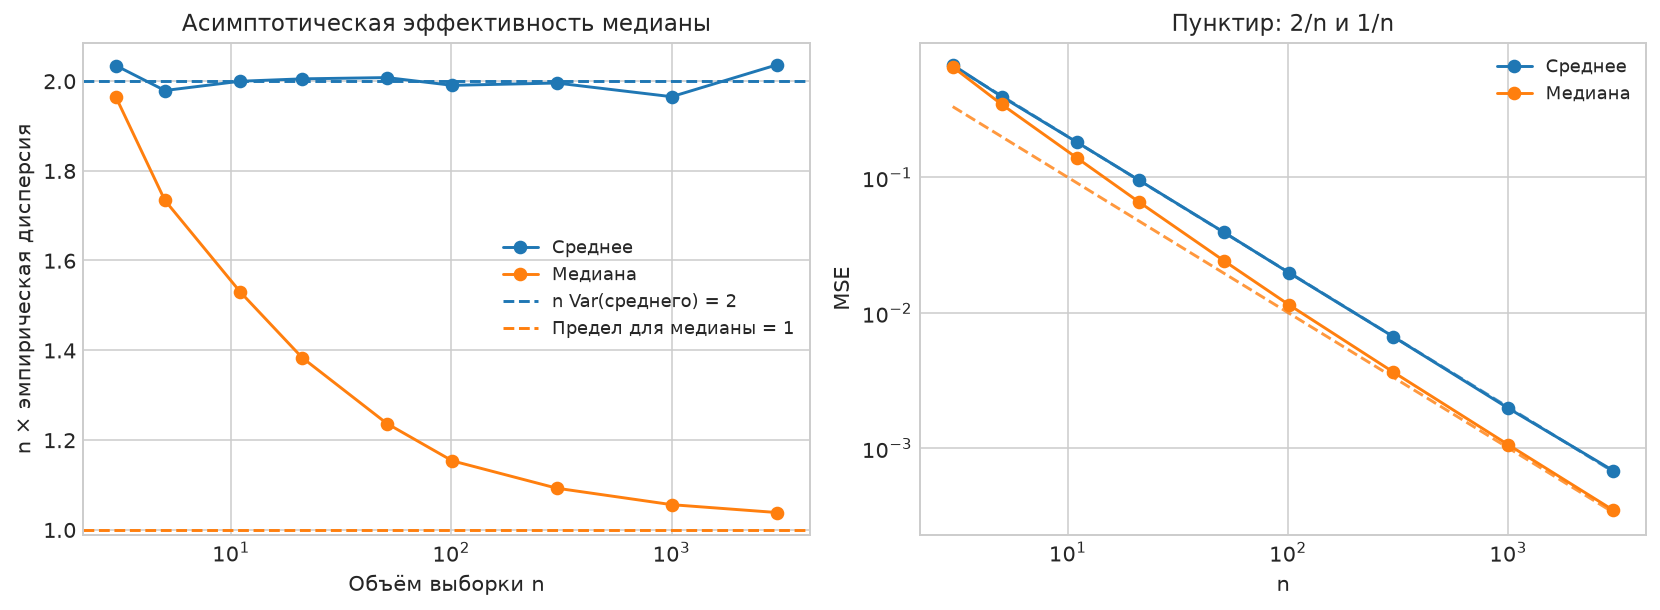

In [10]:
display(Image(filename=str(result_images["variance"])))

## Форма распределений ошибок

Для корректного сравнения нормируем каждую оценку её собственной асимптотической стандартной ошибкой:

$$T_n^{(\mathrm{mean})}=\sqrt{n/2}(\overline X_n-\mu),\qquad
T_n^{(\mathrm{median})}=\sqrt n(\widetilde X_n-\mu).$$

Обе величины должны сходиться к $\mathcal N(0,1)$.
Гистограммы показывают центральную форму, а Q–Q графики лучше выявляют расхождение в хвостах, которые определяют покрытие.
Если хвосты стандартизованной ошибки шире нормальных, фиксированные пороги $\pm1.96$ пропускают больше $5\%$ реализаций.
На больших объёмах отличие медианного распределения становится небольшим визуально, но всё ещё заметным по точным вероятностям покрытия.

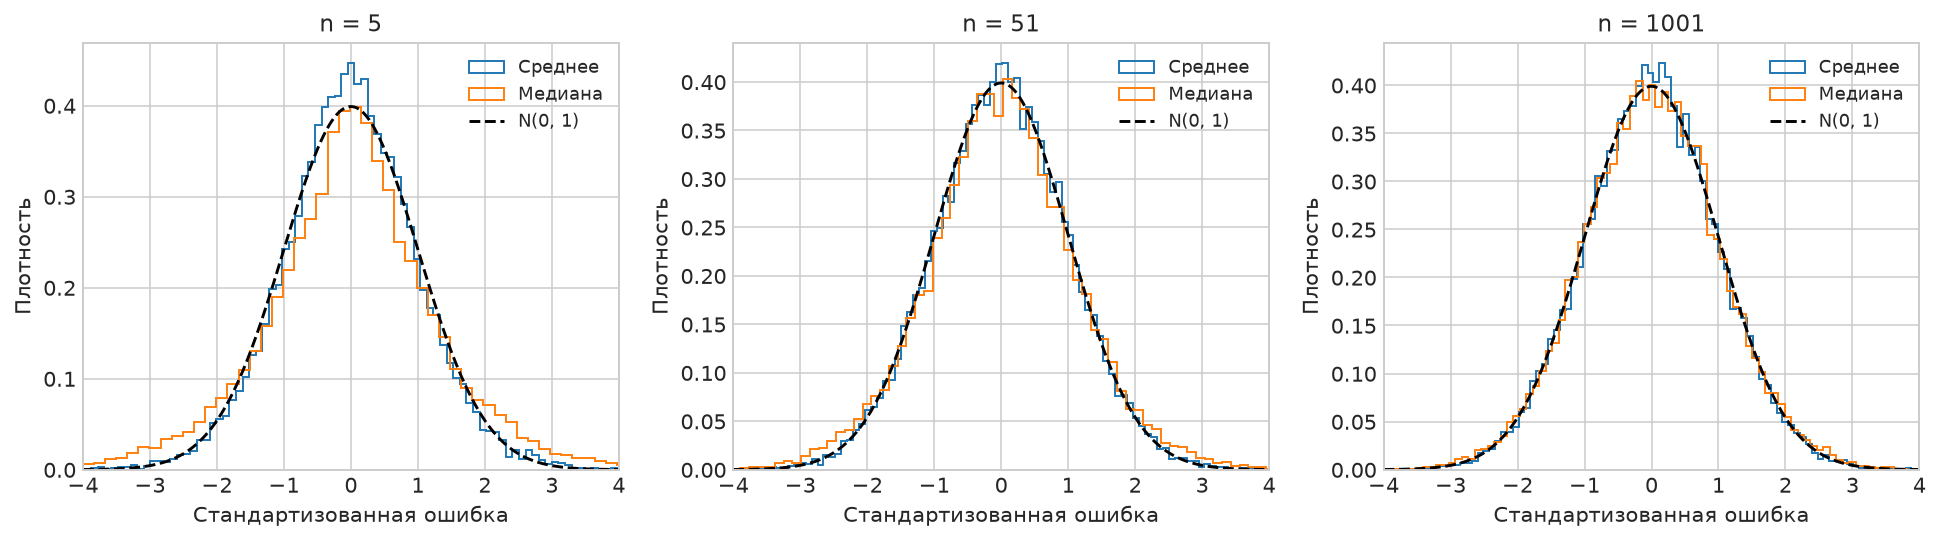

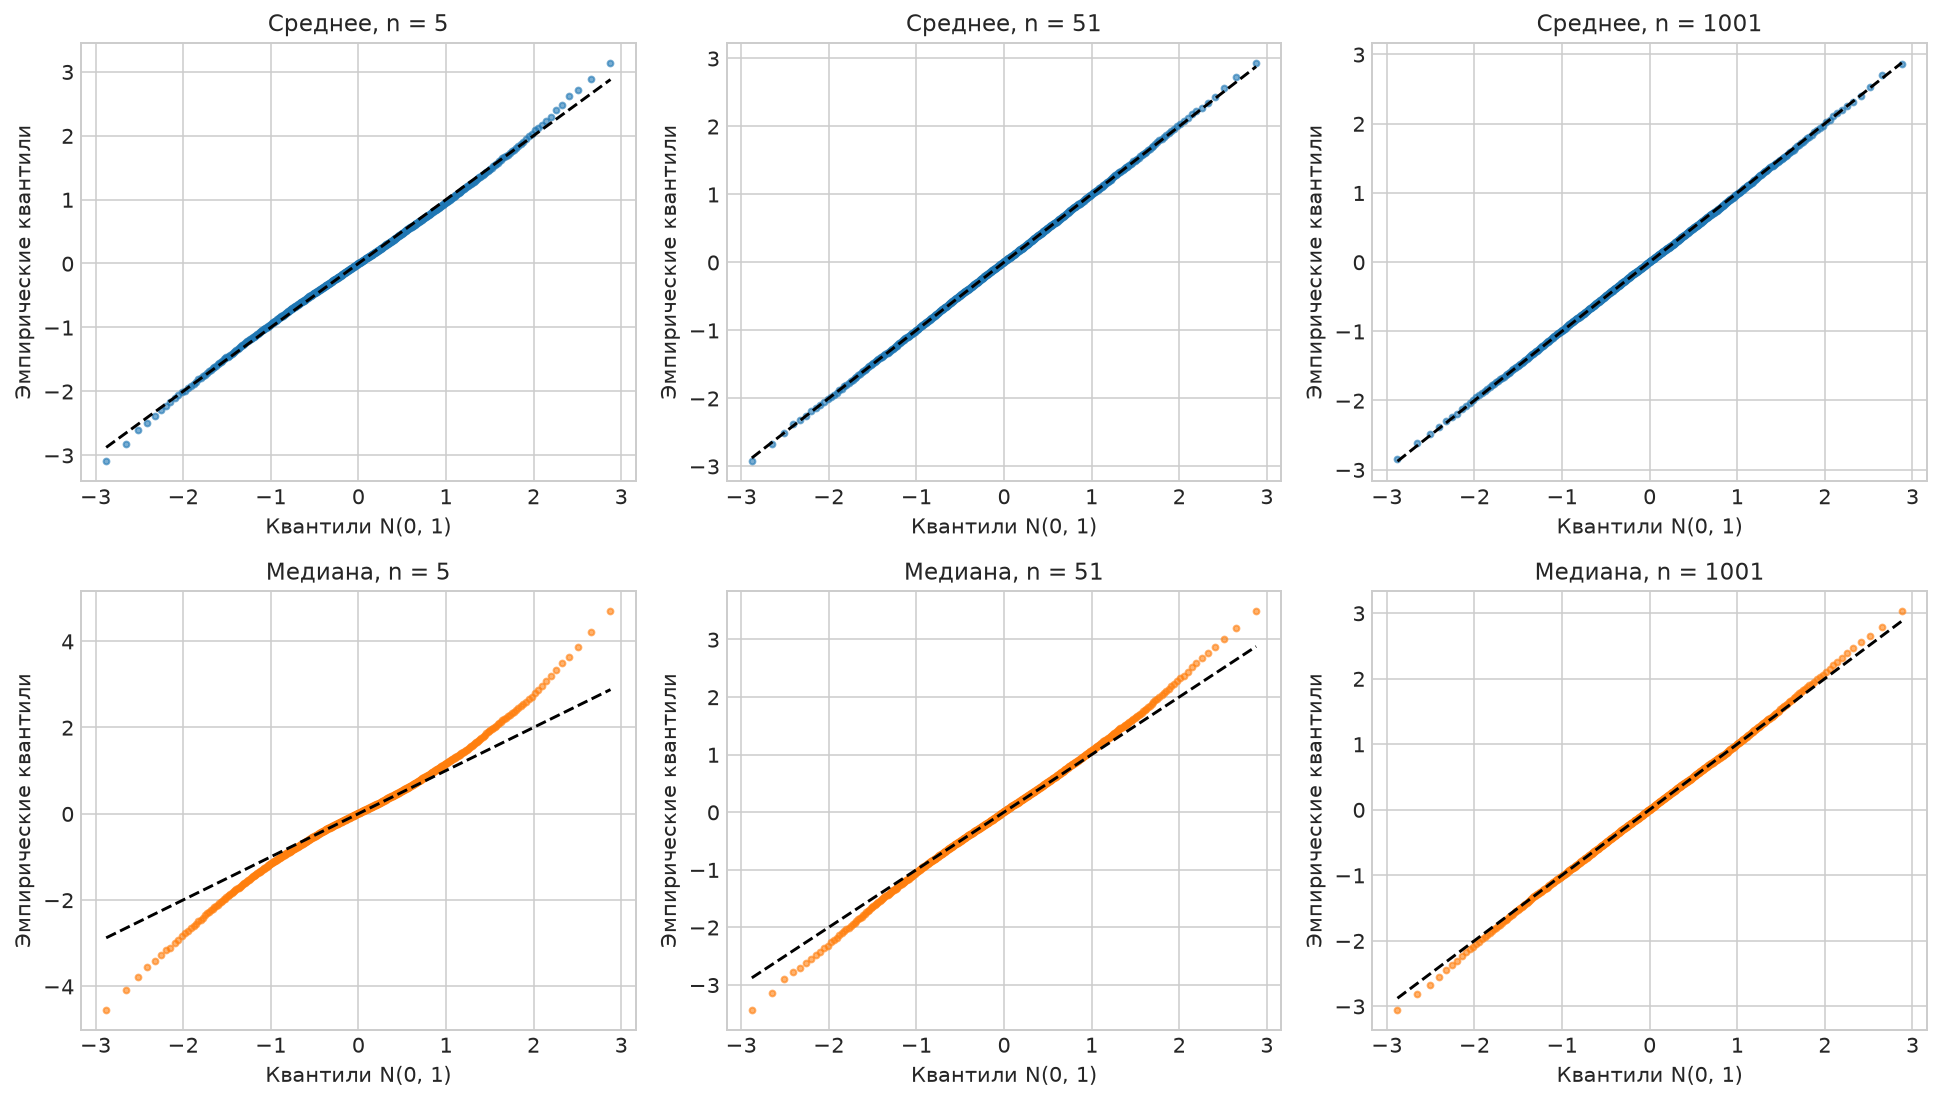

In [11]:
display(Image(filename=str(result_images["distribution"])))
display(Image(filename=str(result_images["qq"])))

## Симметрия, смещение и границы

Благодаря симметрии распределения и симметричности полуширины

$$\mathbb P(U<\mu)=\mathbb P(L>\mu)=\frac{1-c(n)}2.$$

Для точного $95\%$ покрытия оба хвоста были бы по $2.5\%$; при недопокрытии оба превышают это значение одновременно.
Такой рисунок отличается от ситуации со смещённой оценкой, когда один хвост систематически доминирует над другим.

На панели смещения ориентиром служат полосы $\pm1.96\sqrt{\widehat{\operatorname{Var}}(\widehat\mu)/M}$.
Это оценка масштаба шума среднего по $M$ реализациям, а не доверительный интервал для исходного $\mu$.
На рисунках границ полосы 10–90% отражают разброс отдельных границ, а не ошибку их средних.

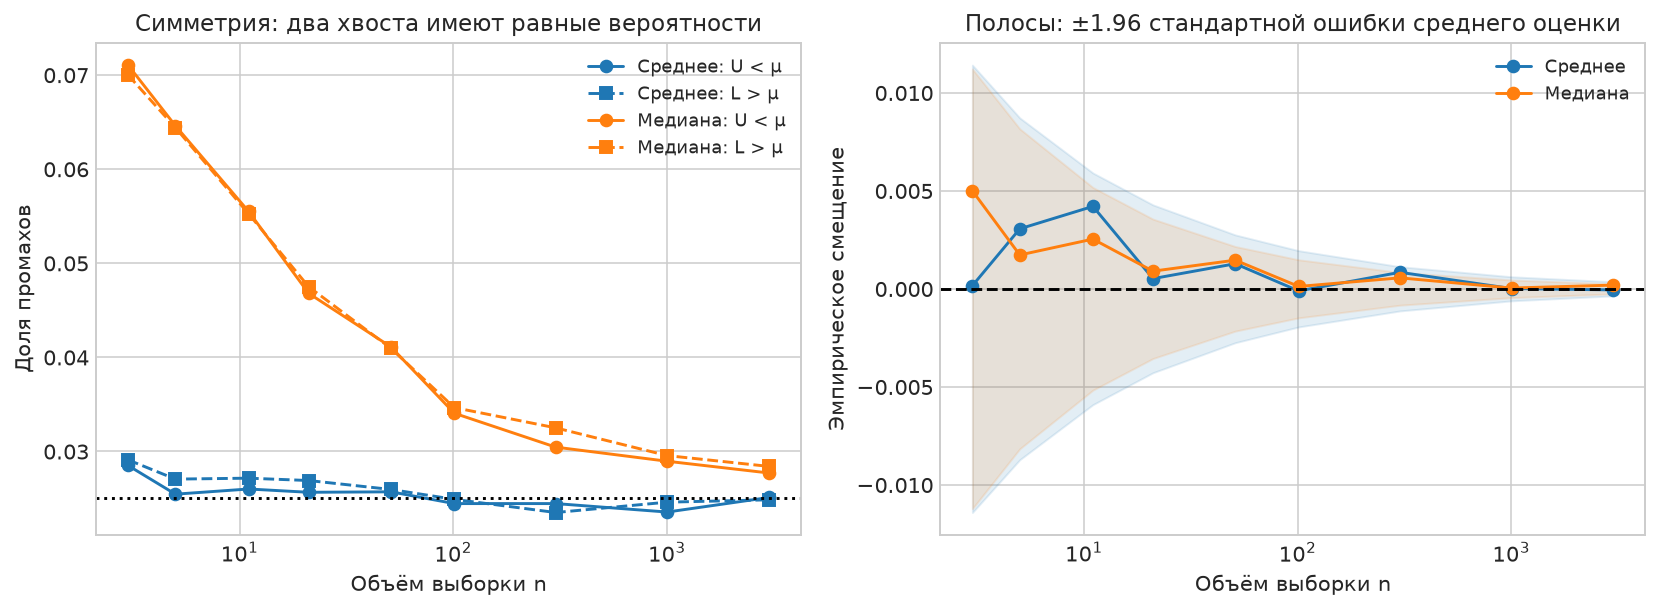

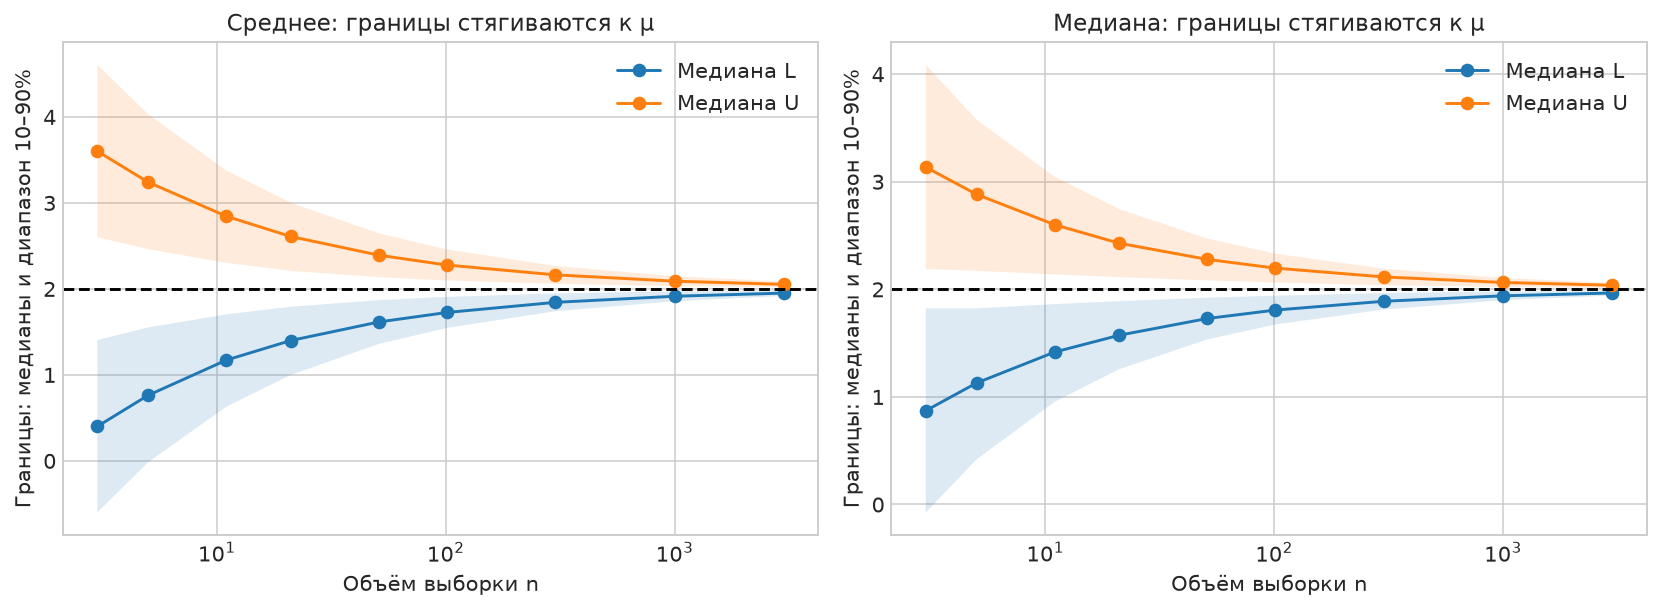

In [12]:
display(Image(filename=str(result_images["tails_bias"])))
display(Image(filename=str(result_images["bounds"])))

## Парное сравнение покрытия

Две процедуры применяются к одним данным, поэтому индикаторы покрытия коррелированы.
Для каждого повторения определим

$$D_j=\mathbb1\{\mu\in I_{\mathrm{median},j}\}-\mathbb1\{\mu\in I_{\mathrm{mean},j}\}\in\{-1,0,1\}.$$

Тогда

$$\widehat\Delta=\frac1M\sum_jD_j,\qquad
\widehat{\operatorname{SE}}(\widehat\Delta)
=\frac{s_D}{\sqrt M},\qquad
s_D^2=\frac1{M-1}\sum_j(D_j-\overline D)^2.$$

Именно эту парную стандартную ошибку используем в полосах на рисунке, а не формулу для двух независимых экспериментов.
Отрицательная разность означает меньшее покрытие медианного интервала.
Это сравнение покрытий, а не попытка выбрать метод только по числу «успешных» повторений.

,n,difference,paired_se
0,3,-0.08345,0.002332
1,5,-0.07650,0.002349
2,11,-0.05760,0.002243
3,21,-0.04175,0.002154
4,51,-0.03040,0.002070
5,101,-0.01935,0.001918
6,301,-0.01500,0.001896
7,1001,-0.01035,0.001851
8,3001,-0.00615,0.001896


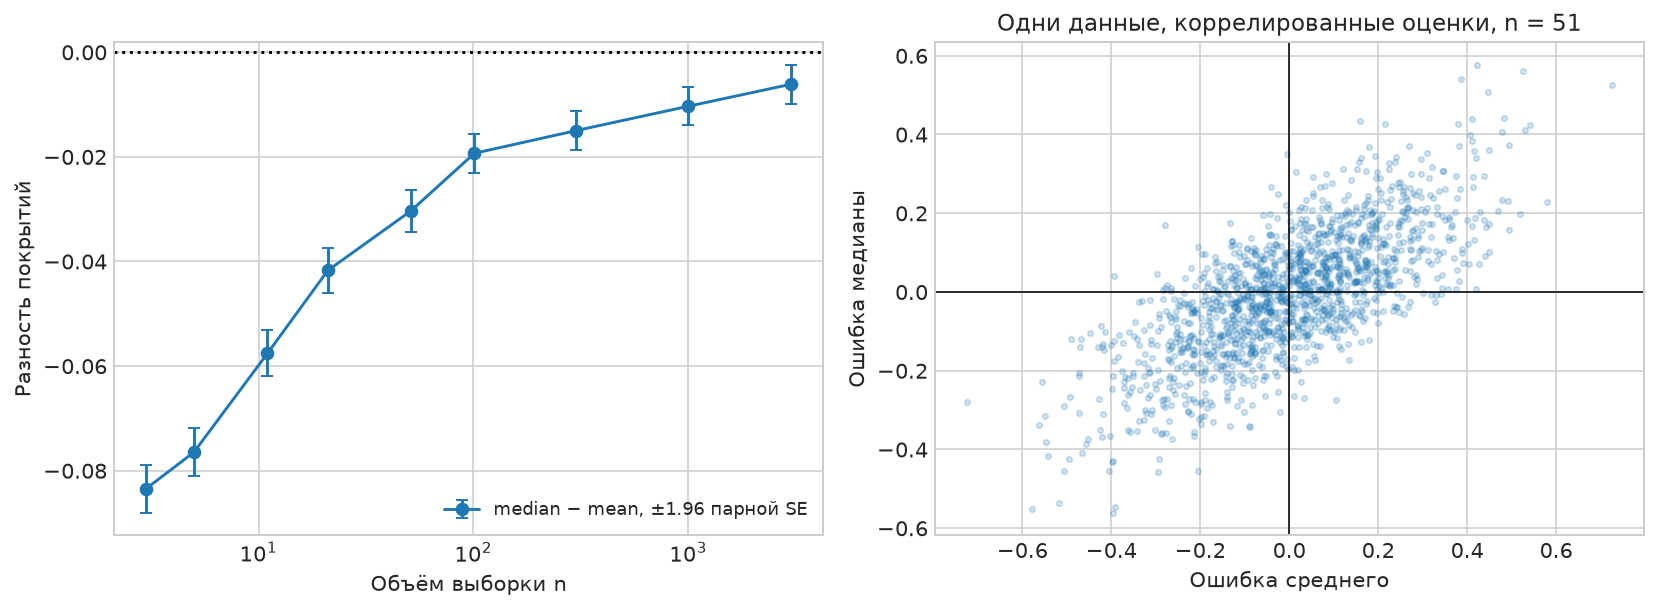

In [13]:
display(paired.round(6))
display(Image(filename=str(result_images["paired"])))

## Чувствительность к доверительному уровню

На рисунке ниже для уровней $90\%$, $95\%$, $99\%$ сопоставляем точное покрытие медианного интервала с номинальным и показываем длину медианного интервала.
Все кривые в этом разделе вычислены по конечновыборочным формулам без нового моделирования.
Увеличение уровня увеличивает $z$, поэтому интервалы расширяются.
Но один лишь более высокий номинальный уровень не устраняет ошибку нормальной аппроксимации: её величина зависит одновременно от $n$ и $\alpha$.

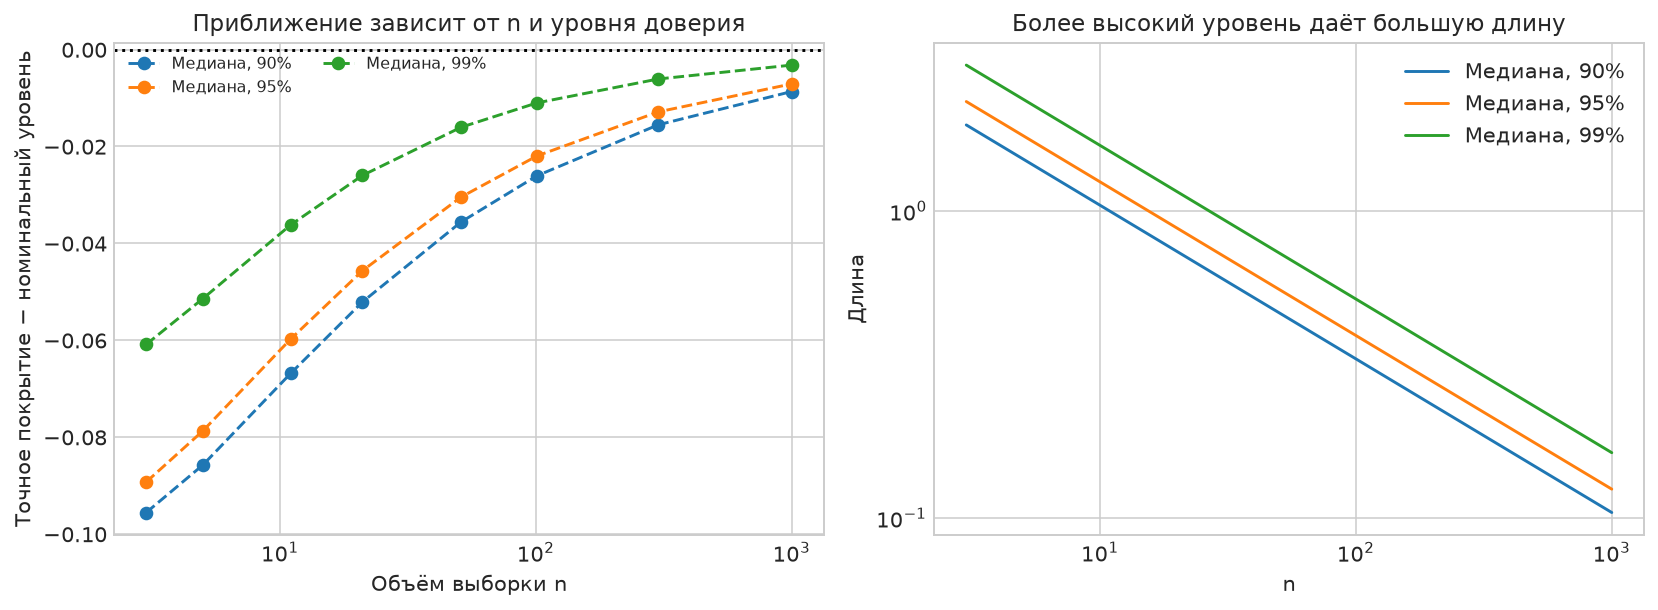

In [14]:
display(Image(filename=str(theory_images["confidence"])))

## Дополнение: точная калибровка медианы

Это дополнительная диагностика; два требуемых асимптотических интервала уже построены и исследованы выше.
Проверим, насколько пришлось бы расширить медианный интервал, чтобы обеспечить точное покрытие $1-\alpha$ при нечётном $n$.

Пусть $U=F(\widetilde X_n)\sim\operatorname{Beta}(k,k)$.
Из симметрии бета-распределения

$$\mathbb P(p_n\le U\le1-p_n)=1-\alpha,\qquad
p_n=F^{-1}_{\operatorname{Beta}(k,k)}(\alpha/2).$$

Для интервала $[\widetilde X_n-h_n,\widetilde X_n+h_n]$ условие покрытия $\mu$ эквивалентно
$F(\mu-h_n)\le U\le F(\mu+h_n)$.
Так как $F(\mu-h_n)=\tfrac12e^{-h_n/b}$, приравниваем его к $p_n$:

$$\frac12e^{-h_n/b}=p_n
\iff-\frac{h_n}b=\log(2p_n)
\iff\boxed{h_n=-b\log(2p_n).}$$

Интервал $[\widetilde X_n-h_n,\widetilde X_n+h_n]$ имеет точное покрытие $1-\alpha$ в модели Лапласа с известным масштабом.
При больших $n$ его полуширина приближается к $zb/\sqrt n$.
На малых $n$ нужное расширение заметно: это наглядно показывает, почему сравнение по одной номинальной длине может вводить в заблуждение.
Точная калибровка не заменяет и не изменяет основной эксперимент с двумя асимптотическими интервалами.

,n,median_asymptotic_length,median_exact_length,mean_asymptotic_length,median_expansion
0,3,2.263171,3.336268,3.200608,1.474156
1,5,1.753045,2.453353,2.479180,1.399481
2,11,1.181903,1.520339,1.671463,1.286349
3,21,0.855398,1.036326,1.209716,1.211513
4,51,0.548900,0.624184,0.776261,1.137154
5,101,0.390047,0.428154,0.551610,1.097698
6,301,0.225941,0.238734,0.319529,1.056621
7,1001,0.123897,0.127741,0.175217,1.031029
8,3001,0.071556,0.072837,0.101195,1.017909


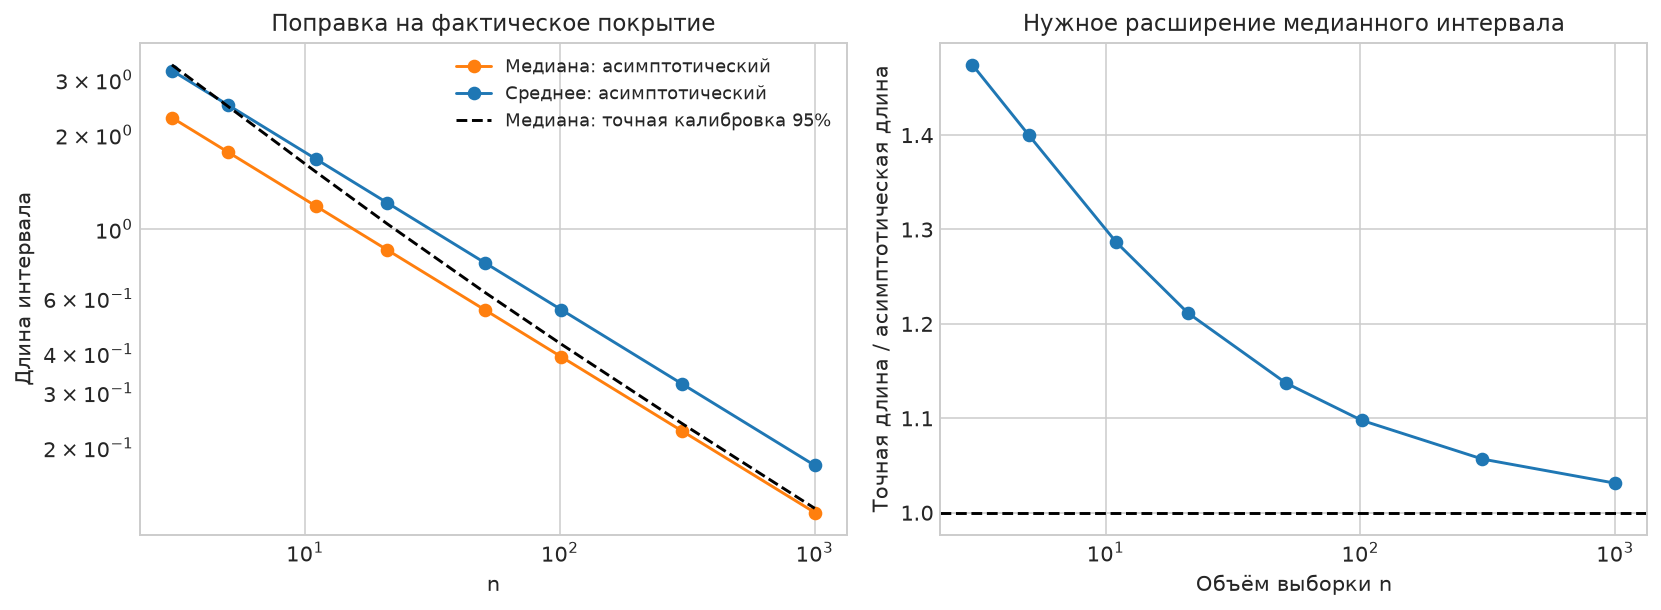

In [15]:
calibration = pd.DataFrame({
    "n": N,
    "median_asymptotic_length": 2*Z/np.sqrt(N),
    "median_exact_length": [2*laplace_median_exact_halfwidth(int(n), ALPHA) for n in N],
    "mean_asymptotic_length": 2*Z*np.sqrt(2/N),
})
calibration["median_expansion"] = calibration.median_exact_length/calibration.median_asymptotic_length
calibration.to_csv(RESULT_DIR / "task_2_calibration.csv", index=False)
display(calibration.round(6))
display(Image(filename=str(theory_images["calibration"])))

In [16]:
# Итоговые числа берём из выполненного эксперимента.
summary = table.set_index(["n", "method"])
parts = []
for n in [5, 101, 3001]:
    mean_row = summary.loc[(n, "mean")]
    median_row = summary.loc[(n, "median")]
    parts.append(
        f"При **n={n}** эмпирическое покрытие: среднее **{mean_row.coverage:.4f}**, "
        f"медиана **{median_row.coverage:.4f}** (точное значение для медианы — "
        f"**{median_row.exact_coverage:.4f}**). "
        f"Длины: **{mean_row.mean_length:.4f}** и **{median_row.mean_length:.4f}**."
    )
display(Markdown("\n\n".join(parts)))

При **n=5** эмпирическое покрытие: среднее **0.9475**, медиана **0.8710** (точное значение для медианы — **0.8713**). Длины: **2.4792** и **1.7530**.

При **n=101** эмпирическое покрытие: среднее **0.9506**, медиана **0.9313** (точное значение для медианы — **0.9280**). Длины: **0.5516** и **0.3900**.

При **n=3001** эмпирическое покрытие: среднее **0.9500**, медиана **0.9439** (точное значение для медианы — **0.9459**). Длины: **0.1012** и **0.0716**.

## Выводы

1. Для $\operatorname{Laplace}(\mu,1)$ получены два асимптотических интервала:

   $$I_{\mathrm{mean}}=[\overline X_n-z\sqrt{2/n},\ \overline X_n+z\sqrt{2/n}],$$
   $$I_{\mathrm{median}}=[\widetilde X_n-z/\sqrt n,\ \widetilde X_n+z/\sqrt n].$$

2. Первый основан на ЦПТ для среднего с дисперсией $2$; второй — на предельной нормальности медианы с коэффициентом дисперсии $1/[4f(\mu)^2]=1$.
3. Медианный интервал в $\sqrt2$ раз короче, а асимптотическая дисперсия медианы вдвое меньше. При больших объёмах это преимущество позволяет получать ту же длину примерно на вдвое меньшей выборке.
4. На малых и умеренных объёмах медианный асимптотический интервал заметно недопокрывает. Интервал среднего в проведённом исследовании гораздо ближе к номинальному покрытию. Меньшую длину нельзя оценивать отдельно от фактической вероятности покрытия.
5. Оба метода состоятельны, обе оценки симметричны и несмещённы. Границы стягиваются к $\mu=2$, длины убывают как $1/\sqrt n$, а вероятности покрытия стремятся к $0.95$.
6. Точная конечновыборочная вероятность покрытия медианного интервала подтвердила, что его отставание от $0.95$ — систематическая ошибка приближения. Дополнительная точная калибровка показала необходимое расширение интервала.

Результаты сохранены в `results/task_2_summary.csv`, `results/task_2_paired.csv`, `results/task_2_calibration.csv`.
Рисунки находятся в `images/laplace_location/` и встроены в выполненный ноутбук.